# Avalon Simulation — Version 2 (belief tracking)

Version 1 gave every player fixed probabilities and ignored the game history, so good won only
about 9% of 7-player games. **Version 2 makes every player learn from the public record:**

* **Team votes.** Every vote is public. Evil players tend to approve teams that contain evil
  and reject all-good teams, so a voting pattern is (noisy) evidence about who is evil.
* **Quest outcomes.** Good players can't play fail, so a quest with *f* fail cards had at
  least *f* evil players on it. That is strong, sometimes conclusive, evidence.

Each agent owns a `BeliefTracker`: an exact Bayesian posterior over **every possible evil team**
(at most C(10, 4) = 210 hypotheses, so this is cheap). All decisions are driven by it:

| Decision | V1 | V2 |
|---|---|---|
| Good leader picks a team | Random seats | Seats weighted towards low-suspicion players |
| Good player votes | Flat 55% approval | Approves if the team is about as safe as the best team they could pick; more lenient as rejections pile up; always approves on the 5th attempt |
| Evil leader picks a team | Self/ally + random seats | Self/ally + seats filled with the good players the table trusts most (so it looks clean) |
| Evil player votes | Fixed rates | Same rates, but sometimes "blends in" by voting on all-good teams as a good player would |
| Evil quest card | Fail 80% | Fail 80%, always fail when it would win the game |

**What changes from V1.** Rules, game state and the engine are copied unchanged. `PlayerView`
gains three public rule constants. The new code is the belief layer (section 4) and the new
agent (section 5). The V1 agent is kept as a baseline so the two can be compared, and even mixed
in one game.

| Layer | V2 status |
|---|---|
| 1. Roles & rules | Unchanged |
| 2. Game state & public log | Unchanged |
| 3. Information model | `PlayerView` adds `n_evil`, `max_rejections`, `quests_to_win` |
| 4. Belief tracking | **New:** `BeliefModel`, `BeliefTracker` |
| 5. Agents / policies | **New:** `V2Params`, `BeliefAgent` (V1 `ProbabilisticAgent` kept) |
| 6. Engine | Unchanged |
| 7–9. Simulation & analysis | Adds belief-accuracy metrics, V1-vs-V2 comparisons, sweeps |

Still out of scope (see the README): special roles such as Merlin, and evil players who
coordinate their fail cards.

## 0. Imports

In [1]:
from __future__ import annotations

import math
import random
from dataclasses import dataclass, field, replace
from enum import Enum
from functools import lru_cache
from itertools import combinations
from typing import Callable, Protocol, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Roles and rules (unchanged from V1)

Official tables: team size per quest, number of evil players, and the rule that
**quest 4 needs two fail cards with 7+ players**.

In [2]:
class Alignment(Enum):
    GOOD = "good"
    EVIL = "evil"


class Role(Enum):
    # (display name, alignment). V3 adds MERLIN, ASSASSIN, PERCIVAL, MORGANA, MORDRED, OBERON.
    LOYAL_SERVANT = ("Loyal Servant of Arthur", Alignment.GOOD)
    MINION = ("Minion of Mordred", Alignment.EVIL)

    def __init__(self, label: str, alignment: Alignment):
        self.label = label
        self.alignment = alignment

    @property
    def is_evil(self) -> bool:
        return self.alignment is Alignment.EVIL


# Official team size for each of the 5 quests, keyed by player count.
# Quest indices are 0-based throughout the code (quest_idx 3 == "quest 4").
QUEST_SIZES = {
    5: [2, 3, 2, 3, 3],
    6: [2, 3, 4, 3, 4],
    7: [2, 3, 3, 4, 4],
    8: [3, 4, 4, 5, 5],
    9: [3, 4, 4, 5, 5],
    10: [3, 4, 4, 5, 5],
}
# Number of evil players for each player count; everyone else is good.
N_EVIL = {5: 2, 6: 2, 7: 3, 8: 3, 9: 3, 10: 4}


@dataclass(frozen=True)
class GameRules:
    # Immutable rulebook for one player count.
    n_players: int
    max_rejections: int = 5      # 5 rejected proposals in a row -> evil wins
    quests_to_win: int = 3

    def __post_init__(self):
        if self.n_players not in QUEST_SIZES:
            raise ValueError("Avalon supports 5-10 players")

    @property
    def n_evil(self) -> int:
        return N_EVIL[self.n_players]

    def team_size(self, quest_idx: int) -> int:
        return QUEST_SIZES[self.n_players][quest_idx]

    def fails_required(self, quest_idx: int) -> int:
        # Fail cards needed to sink a quest. With 7+ players, quest 4 (index 3) needs two.
        return 2 if (self.n_players >= 7 and quest_idx == 3) else 1

    def default_roles(self) -> list[Role]:
        n_good = self.n_players - self.n_evil
        return [Role.LOYAL_SERVANT] * n_good + [Role.MINION] * self.n_evil

## 2. Game state and the public log (unchanged from V1)

`GameState` is the hidden ground truth. `Proposal` and `QuestResult` are the public record
that V2 agents now learn from: **who voted for which team**, and **how many fail cards** each
quest received (never who played them).

In [3]:
# One entry per team proposal, approved or not. Frozen so agents can't rewrite history.
@dataclass(frozen=True)
class Proposal:
    quest_idx: int
    attempt: int                 # 1..5 within this quest
    leader: int
    team: tuple[int, ...]
    votes: dict[int, bool]       # public: who approved / rejected
    approved: bool


# One entry per quest that actually went out (i.e. its team was approved).
@dataclass(frozen=True)
class QuestResult:
    quest_idx: int
    team: tuple[int, ...]
    n_fails: int                 # public: the count only, not who played them
    succeeded: bool


# Mutable, engine-owned state. Only AvalonGame writes to it; agents see a PlayerView instead.
@dataclass
class GameState:
    rules: GameRules
    roles: list[Role]                       # hidden ground truth; roles[i] is player i's role
    leader: int
    quest_idx: int = 0                      # 0-based index of the quest currently being played
    rejections: int = 0                     # consecutive rejections on the current quest
    proposals: list[Proposal] = field(default_factory=list)
    quests: list[QuestResult] = field(default_factory=list)
    winner: Alignment | None = None
    win_reason: str | None = None

    @property
    def n_players(self) -> int:
        return self.rules.n_players

    @property
    def good_score(self) -> int:
        return sum(q.succeeded for q in self.quests)

    @property
    def evil_score(self) -> int:
        return sum(not q.succeeded for q in self.quests)

    def evil_players(self) -> set[int]:
        return {i for i, r in enumerate(self.roles) if r.is_evil}

## 3. Information model

Same as V1: evil players know each other, good players know only themselves. The only change
is that `PlayerView` now also carries three **public rule constants** the V2 agents reason with:
how many players are evil (needed to enumerate hypotheses), the vote-track limit (to recognise
the 5th, must-approve attempt) and the number of quests needed to win (to recognise a
game-deciding quest).

In [4]:
@dataclass(frozen=True)
class PlayerView:
    player_id: int
    role: Role
    known_evil: frozenset[int]        # players this player *knows* are evil (excluding self)
    n_players: int
    n_evil: int                       # V2: public rule constants
    max_rejections: int
    quests_to_win: int
    quest_idx: int
    team_size: int
    fails_required: int
    leader: int
    rejections: int
    good_score: int
    evil_score: int
    proposals: tuple[Proposal, ...]
    quests: tuple[QuestResult, ...]

    @property
    def is_evil(self) -> bool:
        return self.role.is_evil

    @property
    def others(self) -> list[int]:
        return [p for p in range(self.n_players) if p != self.player_id]

    @property
    def is_final_attempt(self) -> bool:
        # Rejecting this proposal would be the 5th in a row and hand evil the win.
        return self.rejections == self.max_rejections - 1


# Signature: (all roles, player id) -> set of players that player knows to be evil.
InformationModel = Callable[[list[Role], int], frozenset[int]]


def basic_knowledge(roles: list[Role], pid: int) -> frozenset[int]:
    # Evil players know each other; good players know nothing.
    if roles[pid].is_evil:
        return frozenset(i for i, r in enumerate(roles) if r.is_evil and i != pid)
    return frozenset()


def make_view(state: GameState, pid: int, knowledge: InformationModel) -> PlayerView:
    # Snapshot of the game from player `pid`'s seat: public state + that player's private info.
    # The log is copied into tuples so an agent can't mutate the engine's lists.
    rules = state.rules
    # After quest 5 resolves, quest_idx becomes 5; clamp so the table lookups stay in range.
    q = min(state.quest_idx, 4)
    return PlayerView(
        player_id=pid,
        role=state.roles[pid],
        known_evil=knowledge(state.roles, pid),
        n_players=state.n_players,
        n_evil=rules.n_evil,
        max_rejections=rules.max_rejections,
        quests_to_win=rules.quests_to_win,
        quest_idx=state.quest_idx,
        team_size=rules.team_size(q),
        fails_required=rules.fails_required(q),
        leader=state.leader,
        rejections=state.rejections,
        good_score=state.good_score,
        evil_score=state.evil_score,
        proposals=tuple(state.proposals),
        quests=tuple(state.quests),
    )

## 4. Belief tracking (new)

### The idea

A **hypothesis** is one possible evil team, e.g. "players 1, 4 and 6 are evil". A player's
belief is a probability for every hypothesis consistent with what they know. A good player
knows they're good, so they start with every evil team that excludes themself, all equally
likely. With 7 players that is C(6, 3) = 20 hypotheses.

After each piece of evidence *E*, every hypothesis *h* is reweighted by **Bayes' rule**:

\[ P(h \mid E) \propto P(E \mid h)\, P(h) \]

Everything a player needs follows from the posterior:

* **Suspicion of player *i*:** \(P(i \text{ evil}) = \sum_{h \ni i} P(h)\).
* **Safety of a team:** P(fewer evil players on the team than the fails needed to sink it).
  This is computed exactly over hypotheses, so it accounts for correlations ("if 2 is evil,
  then 5 probably isn't") that per-player suspicion would miss.

### Likelihoods (the `BeliefModel`)

To compute \(P(E \mid h)\), a player needs a model of how the others behave. That model is
**separate from the real policies**, so we can study a player whose model is wrong.

* **Quest with *f* fails, *k* evil players on the team under *h*:** each evil player is assumed
  to fail with probability *a*, so \(P(f \mid h) = \binom{k}{f} a^f (1-a)^{k-f}\). If
  \(f > k\) the hypothesis is impossible (good can't fail) and is eliminated.
* **Votes:** under *h*, a good voter approves with a fixed rate; an evil voter approves with
  one rate if the team contains evil (under *h*) and another if it doesn't. The leader's vote
  is skipped because everyone approves their own team.

Votes are noisy and the vote model is only approximate, so vote evidence is **tempered**:
its log-likelihood is multiplied by `vote_weight` (0 = ignore votes, 1 = full Bayes). Without
this, a few votes can make a player wrongly certain.

Weights are kept as **log-probabilities** so long games don't underflow to zero.

In [5]:
@dataclass(frozen=True)
class BeliefModel:
    # How an agent *assumes* the others behave. Only used to score evidence; it need not match
    # the real policies (studying a mismatched model is one of the things V2 allows).
    assumed_evil_fail: float = 0.8            # P(an evil player on a quest plays fail)
    vote_good_approve: float = 0.6            # P(a good player approves), for any team
    vote_evil_approve_with_evil: float = 0.9  # P(an evil player approves a team containing evil)
    vote_evil_approve_no_evil: float = 0.3    # P(an evil player approves an all-good team)
    vote_weight: float = 0.5                  # tempering: 0 = ignore votes, 1 = full Bayes

    def __post_init__(self):
        probs = (self.assumed_evil_fail, self.vote_good_approve,
                 self.vote_evil_approve_with_evil, self.vote_evil_approve_no_evil)
        # A probability of exactly 0 or 1 would let one surprising observation eliminate the
        # true hypothesis, after which the posterior can never recover.
        if not all(0 < p < 1 for p in probs):
            raise ValueError("BeliefModel probabilities must be strictly between 0 and 1")
        if not 0 <= self.vote_weight <= 1:
            raise ValueError("vote_weight must be in [0, 1]")


@lru_cache(maxsize=None)
def hypothesis_matrix(n_players: int, n_evil: int, known_good: frozenset[int]) -> np.ndarray:
    # One row per evil team that is consistent with `known_good`; H[h, i] == 1 if player i is
    # evil under hypothesis h. Cached because every agent in every game reuses the same few.
    candidates = [p for p in range(n_players) if p not in known_good]
    H = np.zeros((math.comb(len(candidates), n_evil), n_players), dtype=np.int8)
    for row, evil in enumerate(combinations(candidates, n_evil)):
        H[row, list(evil)] = 1
    H.setflags(write=False)
    return H


class BeliefTracker:
    # Exact posterior over evil teams, updated incrementally from the public log.

    def __init__(self, n_players: int, n_evil: int, model: BeliefModel,
                 known_good: frozenset[int] = frozenset()):
        self.model = model
        self.H = hypothesis_matrix(n_players, n_evil, frozenset(known_good))
        self.log_w = np.zeros(len(self.H))        # uniform prior over hypotheses
        self._n_props = 0                         # how much of the log has been absorbed
        self._n_quests = 0
        self._post: np.ndarray | None = None      # cached normalised posterior

    # ---- evidence ----
    def sync(self, view) -> None:
        # Absorb any log entries added since the last call. Works with a PlayerView or a GameState.
        for prop in view.proposals[self._n_props:]:
            self.observe_votes(prop)
        for quest in view.quests[self._n_quests:]:
            self.observe_quest(quest)
        self._n_props, self._n_quests = len(view.proposals), len(view.quests)

    def observe_votes(self, prop: Proposal) -> None:
        m = self.model
        voters = [p for p in prop.votes if p != prop.leader]
        if m.vote_weight == 0 or not voters:
            return
        approved = np.array([prop.votes[p] for p in voters])
        evil_on_team = self.H[:, list(prop.team)].any(axis=1)                 # per hypothesis
        p_yes_if_evil = np.where(evil_on_team, m.vote_evil_approve_with_evil,
                                 m.vote_evil_approve_no_evil)
        # p_yes[h, v]: P(voter v approves | hypothesis h), depending on v's alignment under h.
        p_yes = np.where(self.H[:, voters] == 1, p_yes_if_evil[:, None], m.vote_good_approve)
        lik = np.where(approved, p_yes, 1 - p_yes)
        self.log_w += m.vote_weight * np.log(lik).sum(axis=1)
        self._post = None

    def observe_quest(self, quest: QuestResult) -> None:
        a, f = self.model.assumed_evil_fail, quest.n_fails
        k = self.H[:, list(quest.team)].sum(axis=1)       # evil players on the team, per hypothesis
        # P(exactly f fails | k evil on team) for k = 0..team size; 0 when f > k.
        table = np.array([math.comb(j, f) * a**f * (1 - a)**(j - f) if j >= f else 0.0
                          for j in range(len(quest.team) + 1)])
        with np.errstate(divide="ignore"):                # log(0) = -inf marks eliminated hypotheses
            self.log_w += np.log(table[k])
        self._post = None

    # ---- queries ----
    @property
    def posterior(self) -> np.ndarray:
        if self._post is None:
            w = np.exp(self.log_w - self.log_w.max())     # subtract max for numerical stability
            self._post = w / w.sum()
        return self._post

    def p_evil(self) -> np.ndarray:
        # Marginal suspicion: entry i is P(player i is evil).
        return self.posterior @ self.H

    def p_team_safe(self, team: Sequence[int], fails_required: int) -> float:
        # P(too few evil on the team to sink the quest), assuming evil fails whenever it can.
        k = self.H[:, list(team)].sum(axis=1)
        return float(self.posterior[k < fails_required].sum())

### Sanity check: one quest result

A 7-player good player (player 0) starts with every other player at 3/6 = 50% suspicion.
Then the team (1, 2) goes on a quest.

* **One fail card:** at least one of 1 and 2 is evil, so both become more suspicious and
  everyone else slightly less (the evil team is partly accounted for). The shift is small
  because with 3 evil among 6 suspects a fail on this team was likely anyway.
* **No fail cards:** a much bigger update. Either both are good, or an evil player chose to
  pass (probability 0.2 under the model), so 1 and 2 drop to about 21%.

The same numbers can be checked by hand: there are 20 hypotheses, and each one is weighted by
the binomial likelihood of the observed fail count.

In [6]:
for n_fails in (1, 0):
    t = BeliefTracker(7, 3, BeliefModel(), known_good=frozenset({0}))
    t.observe_quest(QuestResult(quest_idx=0, team=(1, 2), n_fails=n_fails, succeeded=n_fails == 0))
    print(f"team (1, 2), {n_fails} fail(s): P(evil) = {np.round(t.p_evil(), 2)}, "
          f"P(team (3, 4) is safe) = {t.p_team_safe((3, 4), 1):.2f}")

team (1, 2), 1 fail(s): P(evil) = [0.   0.56 0.56 0.47 0.47 0.47 0.47], P(team (3, 4) is safe) = 0.21
team (1, 2), 0 fail(s): P(evil) = [0.   0.21 0.21 0.65 0.65 0.65 0.65], P(team (3, 4) is safe) = 0.07


## 5. Agents and policies

Same three-method interface as V1, so the engine doesn't change. Two agents:

* **`ProbabilisticAgent`** (copied from V1, unchanged): the fixed-probability baseline.
* **`BeliefAgent`** (new): keeps a `BeliefTracker` and syncs it with the public log at the
  start of every decision.

**Whose beliefs?** A good player's tracker rules out only themself, so it is literally their
belief. An evil player already knows the truth, so their tracker plays a different role: it is
a **public observer** with no private information (every player, including themself, is a
possible suspect). That is a model of what the table can infer, which evil uses to build teams
that look trustworthy and to blend in when voting.

### Good player decisions

* **Propose.** Include self (they know they're good), then fill each remaining seat by
  sampling players with weight \(e^{-\beta_{\text{propose}} \cdot P(\text{evil})}\). A higher
  \(\beta\) means a stronger preference for low-suspicion players; \(\beta = 0\) is V1's random choice.
* **Vote.** Compare the proposed team with the safest team the voter could build themself
  (self plus the least-suspected players):

  \[ P(\text{approve}) = \sigma\big(\beta_{\text{vote}} \cdot (\text{safe}_{\text{team}} - \text{safe}_{\text{best}} + \text{tolerance} + \text{leniency} \cdot \text{rejections})\big) \]

  where \(\sigma\) is the logistic function. The comparison is *relative* on purpose: early in
  the game every team is risky, so an absolute threshold would reject almost everything. The
  leniency term models vote-track pressure, and on the 5th attempt good approves with
  `p_final_attempt_approve`, because rejecting would lose the game outright.

### Evil player decisions

* **Propose.** Like V1, include self and maybe one ally, but fill the remaining seats with the
  *good players the table trusts most*, so the team looks clean and gets approved.
* **Vote.** Approve teams with evil at a high rate. On all-good teams, with probability
  `p_evil_blend_in`, vote as a good player would (using the table's beliefs) instead of
  rejecting at the fixed rate. Constant rejection of clean teams is exactly the pattern the
  vote evidence picks up.
* **Quest card.** Fail with `p_evil_fail`. If one more failed quest wins the game, fail with
  `p_evil_fail_decisive` (default: always).

Coordinating between evil players (e.g. only one of two evil players failing) is left for V4.

In [7]:
class Agent(Protocol):
    def propose_team(self, view: PlayerView) -> tuple[int, ...]: ...
    def vote_on_team(self, view: PlayerView, team: tuple[int, ...]) -> bool: ...
    def play_quest_card(self, view: PlayerView, team: tuple[int, ...]) -> bool: ...  # True = success


# The engine builds agents through a factory, (player id, role, rng) -> Agent, so it never
# depends on a concrete agent class.
AgentFactory = Callable[[int, Role, random.Random], Agent]


def sigmoid(x: float) -> float:
    return 1.0 / (1.0 + math.exp(-x))

### V1 baseline agent (unchanged)

In [8]:
@dataclass(frozen=True)
class PolicyParams:
    # --- team proposal ---
    p_leader_includes_self: float = 0.9
    p_evil_leader_adds_ally: float = 0.3
    # --- team vote ---
    p_approve_own_team: float = 1.0
    p_good_approve: float = 0.55
    p_evil_approve_with_evil: float = 0.9     # team has >= 1 evil player
    p_evil_approve_no_evil: float = 0.3       # all-good team
    # --- quest card ---
    p_evil_fail: float = 0.8


class ProbabilisticAgent:
    # V1 agent: fixed probabilities, uses private knowledge only.

    def __init__(self, pid: int, role: Role, params: PolicyParams, rng: random.Random):
        self.pid, self.role, self.params, self.rng = pid, role, params, rng

    def _chance(self, p: float) -> bool:
        return self.rng.random() < p

    def propose_team(self, view: PlayerView) -> tuple[int, ...]:
        p = self.params
        team: list[int] = []
        if self._chance(p.p_leader_includes_self):
            team.append(self.pid)
        if view.is_evil and view.known_evil and len(team) < view.team_size \
                and self._chance(p.p_evil_leader_adds_ally):
            team.append(self.rng.choice(sorted(view.known_evil)))
        pool = [i for i in range(view.n_players) if i not in team]
        team += self.rng.sample(pool, view.team_size - len(team))
        return tuple(sorted(team))

    def vote_on_team(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        p = self.params
        if view.leader == self.pid:
            return self._chance(p.p_approve_own_team)
        if not view.is_evil:
            return self._chance(p.p_good_approve)
        evil_on_team = any(i == self.pid or i in view.known_evil for i in team)
        return self._chance(p.p_evil_approve_with_evil if evil_on_team else p.p_evil_approve_no_evil)

    def play_quest_card(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        if not view.is_evil:
            return True
        return not self._chance(self.params.p_evil_fail)


def probabilistic_factory(params: PolicyParams | None = None) -> AgentFactory:
    params = params or PolicyParams()
    return lambda pid, role, rng: ProbabilisticAgent(pid, role, params, rng)

### V2 belief-driven agent

In [9]:
@dataclass(frozen=True)
class V2Params:
    # --- good: proposing ---
    p_good_leader_includes_self: float = 1.0
    propose_beta: float = 8.0               # seat weight exp(-beta * P(evil)); 0 = random (V1)
    # --- good: voting ---
    vote_beta: float = 12.0                 # steepness of the approval curve
    vote_tolerance: float = 0.1             # accept teams this much less safe than my best team
    vote_leniency: float = 0.05             # extra tolerance per rejection already on the track
    p_final_attempt_approve: float = 0.95   # 5th attempt: rejecting loses the game outright
    p_approve_own_team: float = 1.0
    # --- evil: proposing ---
    p_evil_leader_includes_self: float = 0.9
    p_evil_leader_adds_ally: float = 0.3
    evil_propose_beta: float = 8.0          # fill seats with good players the table trusts
    # --- evil: voting ---
    p_evil_approve_with_evil: float = 0.9
    p_evil_approve_no_evil: float = 0.3
    p_evil_blend_in: float = 0.3            # on all-good teams, vote like a good player would
    # --- evil: quest card ---
    p_evil_fail: float = 0.8
    p_evil_fail_decisive: float = 1.0       # when one more failed quest wins the game
    # --- how every agent interprets evidence ---
    belief: BeliefModel = BeliefModel()


class BeliefAgent:
    # V2 agent: same decisions as V1, but the probabilities come from a BeliefTracker.

    def __init__(self, pid: int, role: Role, params: V2Params, rng: random.Random):
        self.pid, self.role, self.params, self.rng = pid, role, params, rng
        self.beliefs: BeliefTracker | None = None   # created on first view (needs n_players, n_evil)

    def _chance(self, p: float) -> bool:
        return self.rng.random() < p

    def _update(self, view: PlayerView) -> BeliefTracker:
        if self.beliefs is None:
            # Evil must not rule itself out: the true evil team has to stay among the hypotheses,
            # otherwise the evidence can eventually eliminate all of them.
            known_good = frozenset() if view.is_evil else frozenset({self.pid})
            self.beliefs = BeliefTracker(view.n_players, view.n_evil, self.params.belief, known_good)
        self.beliefs.sync(view)
        return self.beliefs

    def _pick_trusted(self, pool: list[int], p_evil: np.ndarray, k: int, beta: float) -> list[int]:
        # Weighted sampling without replacement: low-suspicion players are favoured, but not
        # deterministically, so beta controls how strongly beliefs shape the team.
        pool = list(pool)
        weights = [math.exp(-beta * p_evil[i]) for i in pool]
        chosen = []
        for _ in range(k):
            j = self.rng.choices(range(len(pool)), weights=weights)[0]
            chosen.append(pool.pop(j))
            weights.pop(j)
        return chosen

    def _best_team(self, view: PlayerView, b: BeliefTracker) -> tuple[int, ...]:
        # The team this seat would consider safest: itself plus the least-suspected others.
        p_evil = b.p_evil()
        others = sorted(view.others, key=lambda i: p_evil[i])
        return (self.pid, *others[:view.team_size - 1])

    def _good_approval(self, view: PlayerView, team: tuple[int, ...], b: BeliefTracker) -> float:
        p = self.params
        if view.is_final_attempt:
            return p.p_final_attempt_approve
        safe = b.p_team_safe(team, view.fails_required)
        best = b.p_team_safe(self._best_team(view, b), view.fails_required)
        margin = safe - best + p.vote_tolerance + p.vote_leniency * view.rejections
        return sigmoid(p.vote_beta * margin)

    # ---- the three decisions ----
    def propose_team(self, view: PlayerView) -> tuple[int, ...]:
        p, b = self.params, self._update(view)
        if not view.is_evil:
            team = [self.pid] if self._chance(p.p_good_leader_includes_self) else []
            team += self._pick_trusted(view.others, b.p_evil(), view.team_size - len(team),
                                       p.propose_beta)
            return tuple(sorted(team))

        team = [self.pid] if self._chance(p.p_evil_leader_includes_self) else []
        if view.known_evil and len(team) < view.team_size and self._chance(p.p_evil_leader_adds_ally):
            team.append(self.rng.choice(sorted(view.known_evil)))
        # Remaining seats go to good players only (evil knows who they are), favouring the ones
        # the table trusts, so the team looks clean.
        good = [i for i in view.others if i not in view.known_evil]
        team += self._pick_trusted(good, b.p_evil(), view.team_size - len(team), p.evil_propose_beta)
        return tuple(sorted(team))

    def vote_on_team(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        p, b = self.params, self._update(view)
        if view.leader == self.pid:
            return self._chance(p.p_approve_own_team)
        if not view.is_evil:
            return self._chance(self._good_approval(view, team, b))
        if any(i == self.pid or i in view.known_evil for i in team):
            return self._chance(p.p_evil_approve_with_evil)
        if self._chance(p.p_evil_blend_in):
            return self._chance(self._good_approval(view, team, b))
        return self._chance(p.p_evil_approve_no_evil)

    def play_quest_card(self, view: PlayerView, team: tuple[int, ...]) -> bool:
        if not view.is_evil:
            return True
        p = self.params
        decisive = view.evil_score == view.quests_to_win - 1
        return not self._chance(p.p_evil_fail_decisive if decisive else p.p_evil_fail)


def belief_factory(params: V2Params | None = None) -> AgentFactory:
    params = params or V2Params()
    return lambda pid, role, rng: BeliefAgent(pid, role, params, rng)


def mixed_factory(good: AgentFactory, evil: AgentFactory) -> AgentFactory:
    # Different agent types per side, e.g. learning good players against V1 evil players.
    return lambda pid, role, rng: (evil if role.is_evil else good)(pid, role, rng)

## 6. Game engine (unchanged from V1)

The engine enforces the rules and never looks inside the agents, which is why V2 needs no
changes here: agents pull what they need from their `PlayerView`.

In [10]:
class AvalonGame:
    def __init__(
        self,
        n_players: int,
        agent_factory: AgentFactory,
        rng: random.Random | None = None,
        knowledge: InformationModel = basic_knowledge,
        roles: list[Role] | None = None,
    ):
        # One shared RNG drives role dealing, the first leader and every agent decision,
        # so a seed fully reproduces a game.
        self.rng = rng or random.Random()
        self.rules = GameRules(n_players)
        roles = list(roles or self.rules.default_roles())
        if len(roles) != n_players:
            raise ValueError(f"Got {len(roles)} roles for {n_players} players")
        self.rng.shuffle(roles)                     # deal roles to seats at random
        self.knowledge = knowledge
        self.state = GameState(rules=self.rules, roles=roles, leader=self.rng.randrange(n_players))
        self.agents = [agent_factory(i, r, self.rng) for i, r in enumerate(roles)]

    def view(self, pid: int) -> PlayerView:
        return make_view(self.state, pid, self.knowledge)

    # ---- phases ----
    def _propose(self) -> tuple[int, ...]:
        s = self.state
        team = tuple(self.agents[s.leader].propose_team(self.view(s.leader)))
        size = self.rules.team_size(s.quest_idx)
        if len(set(team)) != size or not all(0 <= p < s.n_players for p in team):
            raise ValueError(f"Invalid team {team} from leader {s.leader}")
        return team

    def _vote(self, team: tuple[int, ...]) -> dict[int, bool]:
        # Every player votes, including the leader. All votes see the same pre-vote view,
        # i.e. they are effectively simultaneous, as in the real game.
        return {p: bool(self.agents[p].vote_on_team(self.view(p), team)) for p in range(self.state.n_players)}

    def _run_quest(self, team: tuple[int, ...]) -> QuestResult:
        s = self.state
        fails = 0
        for p in team:
            success = self.agents[p].play_quest_card(self.view(p), team)
            if not s.roles[p].is_evil:
                success = True                      # rule enforcement: good can't fail
            fails += not success
        return QuestResult(s.quest_idx, team, fails, fails < self.rules.fails_required(s.quest_idx))

    def _end_of_game(self) -> None:
        s = self.state
        if s.good_score >= self.rules.quests_to_win:
            s.winner, s.win_reason = Alignment.GOOD, "3 quests succeeded"
        elif s.evil_score >= self.rules.quests_to_win:
            s.winner, s.win_reason = Alignment.EVIL, "3 quests failed"

    # ---- main loop ----
    def step(self) -> None:
        # One proposal (+ vote, + quest if approved).
        s = self.state
        team = self._propose()
        votes = self._vote(team)
        approved = sum(votes.values()) > s.n_players / 2      # strict majority; ties reject
        s.proposals.append(Proposal(s.quest_idx, s.rejections + 1, s.leader, team, votes, approved))
        s.leader = (s.leader + 1) % s.n_players               # leadership passes clockwise either way

        if not approved:
            s.rejections += 1
            if s.rejections >= self.rules.max_rejections:
                s.winner, s.win_reason = Alignment.EVIL, "5 rejected proposals"
            return

        s.rejections = 0                                      # vote track resets once a team goes
        s.quests.append(self._run_quest(team))
        s.quest_idx += 1
        self._end_of_game()

    def play(self) -> GameState:
        while self.state.winner is None:
            self.step()
        return self.state

## 7. One game, step by step

`replay_beliefs` replays a finished game's public log through a fresh tracker that has **no
private information** (a "public observer"). That is the shared core of every good player's
beliefs; each good player additionally rules themself out. The table below shows how the
observer's suspicion of each player evolves; evil players are marked with `*`.

In [11]:
def describe_game(state: GameState) -> None:
    evil = sorted(state.evil_players())
    print(f"Evil players: {evil}")
    for prop in state.proposals:
        yes = [p for p, v in prop.votes.items() if v]
        tag = "APPROVED" if prop.approved else "rejected"
        print(f"Q{prop.quest_idx + 1} try {prop.attempt}: leader {prop.leader} proposes {prop.team} "
              f"-> {tag} (yes: {yes})")
        if prop.approved:
            q = next(q for q in state.quests if q.quest_idx == prop.quest_idx)
            print(f"     quest {'SUCCESS' if q.succeeded else 'FAIL'} ({q.n_fails} fail card(s))")
    print(f"\nWinner: {state.winner.value.upper()} ({state.win_reason}); "
          f"score good {state.good_score} - evil {state.evil_score}")


def replay_beliefs(state: GameState, model: BeliefModel = BeliefModel()) -> np.ndarray:
    # Row s = public P(evil) for every player after s quests (row 0 = prior).
    tracker = BeliefTracker(state.n_players, state.rules.n_evil, model)
    rows = [tracker.p_evil()]
    for quest in state.quests:
        for prop in state.proposals:
            if prop.quest_idx == quest.quest_idx:
                tracker.observe_votes(prop)
        tracker.observe_quest(quest)
        rows.append(tracker.p_evil())
    return np.array(rows)


game = AvalonGame(7, belief_factory(), rng=random.Random(16))
state = game.play()
describe_game(state)

evil = state.evil_players()
beliefs = pd.DataFrame(replay_beliefs(state),
                       index=["prior"] + [f"after Q{q.quest_idx + 1}" for q in state.quests],
                       columns=[f"P{i}{'*' if i in evil else ''}" for i in range(state.n_players)])
display(beliefs.round(2))

Evil players: [0, 3, 4]
Q1 try 1: leader 3 proposes (3, 5) -> rejected (yes: [0, 3, 4])
Q1 try 2: leader 4 proposes (3, 4) -> rejected (yes: [0, 3, 4])
Q1 try 3: leader 5 proposes (4, 5) -> APPROVED (yes: [0, 3, 4, 5])
     quest FAIL (1 fail card(s))
Q2 try 1: leader 6 proposes (1, 5, 6) -> APPROVED (yes: [0, 1, 2, 4, 6])
     quest SUCCESS (0 fail card(s))
Q3 try 1: leader 0 proposes (0, 4, 5) -> rejected (yes: [0, 3])
Q3 try 2: leader 1 proposes (1, 2, 5) -> APPROVED (yes: [1, 2, 4, 5, 6])
     quest SUCCESS (0 fail card(s))
Q4 try 1: leader 2 proposes (1, 2, 5, 6) -> APPROVED (yes: [1, 2, 4, 5, 6])
     quest SUCCESS (0 fail card(s))

Winner: GOOD (3 quests succeeded); score good 3 - evil 1


,P0*,P1,P2,P3*,P4*,P5,P6
prior,0.43,0.43,0.43,0.43,0.43,0.43,0.43
after Q1,0.79,0.14,0.14,0.71,0.79,0.27,0.14
after Q2,0.90,0.06,0.11,0.87,0.97,0.04,0.05
after Q3,0.99,0.00,0.01,0.99,1.00,0.00,0.01
after Q4,1.00,0.00,0.00,1.00,1.00,0.00,0.00


## 8. Monte Carlo: V1 vs V2 over 5,000 games

`run_games` keeps the full `GameState` of every game so several metrics can be computed from
the same games. Three matchups are compared:

* **V1:** both sides use the fixed-probability agent (the V1 baseline).
* **V2 good vs V1 evil:** only good learns. This isolates the value of belief tracking.
* **V2:** both sides use `BeliefAgent`, so evil also adapts (trusted-looking teams, blending in).

Game *g* uses seed *g* in every matchup, so all three see the same role deals and first leaders.

In [12]:
def run_games(n_games: int, n_players: int, agent_factory: AgentFactory, seed: int = 0) -> list[GameState]:
    return [AvalonGame(n_players, agent_factory, rng=random.Random(seed + g)).play()
            for g in range(n_games)]


def game_record(state: GameState) -> dict:
    evil = state.evil_players()
    return {
        "winner": state.winner.value,
        "reason": state.win_reason,
        "good_score": state.good_score,
        "evil_score": state.evil_score,
        "n_quests": len(state.quests),
        "n_proposals": len(state.proposals),
        "n_rejected": sum(not p.approved for p in state.proposals),
        "quest_outcomes": "".join("S" if q.succeeded else "F" for q in state.quests),
        # NaN when the game ended on the vote track before any quest went out.
        "clean_team_share": (np.mean([not (set(q.team) & evil) for q in state.quests])
                             if state.quests else np.nan),
    }


def records(states: list[GameState]) -> pd.DataFrame:
    return pd.DataFrame([game_record(s) for s in states])


def simulate(n_games: int, n_players: int, agent_factory: AgentFactory, seed: int = 0) -> pd.DataFrame:
    return records(run_games(n_games, n_players, agent_factory, seed))


MATCHUPS = {
    "V1": probabilistic_factory(),
    "V2 good vs V1 evil": mixed_factory(good=belief_factory(), evil=probabilistic_factory()),
    "V2": belief_factory(),
}

In [13]:
N_GAMES = 5000
states = {name: run_games(N_GAMES, 7, f) for name, f in MATCHUPS.items()}
dfs = {name: records(s) for name, s in states.items()}

summary = pd.DataFrame({
    name: {
        "good win rate": (df.winner == "good").mean(),
        "evil: 3 failed quests": (df.reason == "3 quests failed").mean(),
        "evil: 5 rejections": (df.reason == "5 rejected proposals").mean(),
        "quest teams with no evil": df.clean_team_share.mean(),
        "proposals per game": df.n_proposals.mean(),
        "rejections per game": df.n_rejected.mean(),
    } for name, df in dfs.items()
}).round(3)
display(summary)

,V1,V2 good vs V1 evil,V2
good win rate,0.092,0.967,0.963
evil: 3 failed quests,0.908,0.023,0.035
evil: 5 rejections,0.000,0.010,0.002
quest teams with no evil,0.069,0.686,0.612
proposals per game,4.316,8.664,7.173
rejections per game,0.523,4.749,3.195


### Win rate and how games end

The left chart is the headline: how much does learning from the public record help good?
The right chart splits each matchup's games by how they ended.

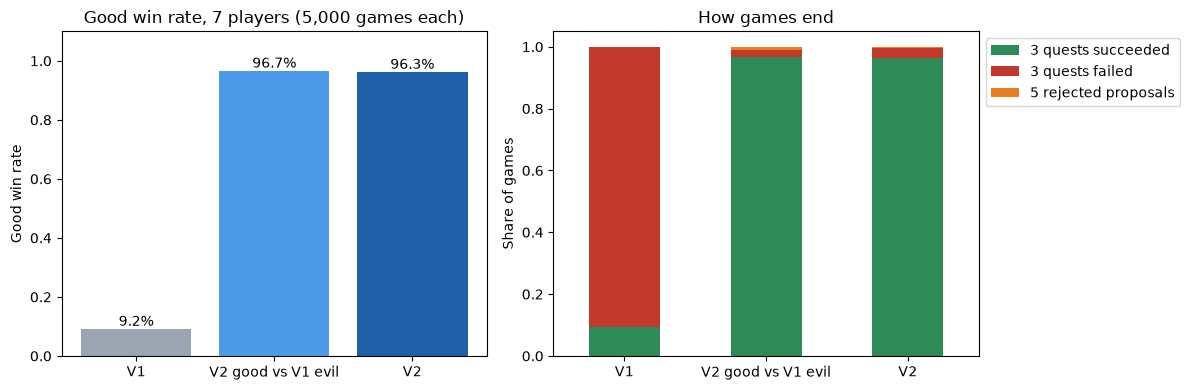

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#9aa5b1", "#4c9be8", "#1f5fa8"]

rates = [(df.winner == "good").mean() for df in dfs.values()]
ax1.bar(dfs.keys(), rates, color=colors)
for i, r in enumerate(rates):
    ax1.text(i, r + 0.01, f"{r:.1%}", ha="center")
ax1.set_ylim(0, 1.1); ax1.set_ylabel("Good win rate")
ax1.set_title(f"Good win rate, 7 players ({N_GAMES:,} games each)")

reasons = ["3 quests succeeded", "3 quests failed", "5 rejected proposals"]
shares = pd.DataFrame({n: df.reason.value_counts(normalize=True) for n, df in dfs.items()}).T
shares = shares.reindex(columns=reasons, fill_value=0).fillna(0)
shares.plot.bar(stacked=True, ax=ax2, color=["#2e8b57", "#c0392b", "#e67e22"], rot=0)
ax2.set_ylabel("Share of games"); ax2.set_title("How games end")
ax2.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

### Are the beliefs accurate?

For every V2 game, replay the public log and measure after each quest:

* **Mean suspicion** assigned to the players who really are evil vs. those who are good.
  At the start both equal the prior \(n_{\text{evil}} / n\). Good learning makes them diverge.
* **Top-k accuracy:** of the *k* most-suspected players (*k* = number of evil players), the
  share that really are evil. Guessing at random gives \(k / n\).

Later stages only include games that lasted that long, so the sample shrinks to the right.

,p_evil_if_evil,p_evil_if_good,top_k_accuracy,n_games
stage,,,,
0,0.429,0.429,0.428,5000
1,0.547,0.340,0.632,4993
2,0.724,0.207,0.860,4992
3,0.849,0.113,0.927,4989
4,0.921,0.060,0.969,3776
5,0.983,0.013,0.999,1138


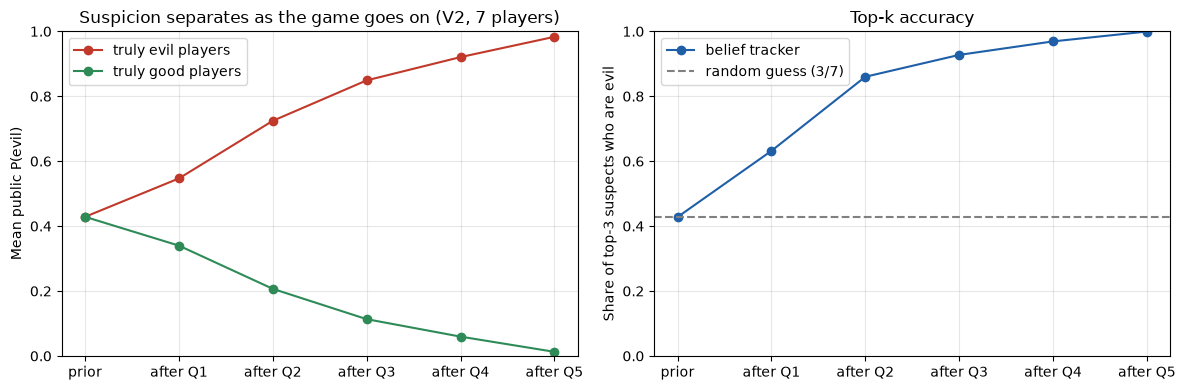

In [15]:
def belief_metrics(states: list[GameState], model: BeliefModel = BeliefModel()) -> pd.DataFrame:
    rows = []
    for g, s in enumerate(states):
        evil = np.array([r.is_evil for r in s.roles])
        k = s.rules.n_evil
        for stage, p in enumerate(replay_beliefs(s, model)):
            top_k = np.argsort(-p)[:k]
            rows.append({"game": g, "stage": stage,
                         "p_evil_if_evil": p[evil].mean(), "p_evil_if_good": p[~evil].mean(),
                         "top_k_accuracy": evil[top_k].mean()})
    return pd.DataFrame(rows)


bm = belief_metrics(states["V2"], V2Params().belief)
by_stage = bm.groupby("stage").agg(
    p_evil_if_evil=("p_evil_if_evil", "mean"), p_evil_if_good=("p_evil_if_good", "mean"),
    top_k_accuracy=("top_k_accuracy", "mean"), n_games=("game", "count"))
display(by_stage.round(3))

labels = ["prior"] + [f"after Q{i}" for i in range(1, len(by_stage))]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(labels, by_stage.p_evil_if_evil, marker="o", color="#c0392b", label="truly evil players")
ax1.plot(labels, by_stage.p_evil_if_good, marker="o", color="#2e8b57", label="truly good players")
ax1.set_ylim(0, 1); ax1.set_ylabel("Mean public P(evil)"); ax1.legend()
ax1.set_title("Suspicion separates as the game goes on (V2, 7 players)")
ax2.plot(labels, by_stage.top_k_accuracy, marker="o", color="#1f5fa8", label="belief tracker")
ax2.axhline(3 / 7, ls="--", color="gray", label="random guess (3/7)")
ax2.set_ylim(0, 1); ax2.set_ylabel("Share of top-3 suspects who are evil"); ax2.legend()
ax2.set_title("Top-k accuracy")
for ax in (ax1, ax2):
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Do good players build cleaner teams?

Share of quest teams with **no** evil player on them, by quest number. In V1 this only
depends on team size. In V2 it rises over the game as good players learn whom to leave out.

Quest 4 is the exception, and it is intended behaviour: with 7+ players it needs *two* fail
cards, so `p_team_safe` correctly treats a team with a single evil player as safe, and good
players approve such teams.

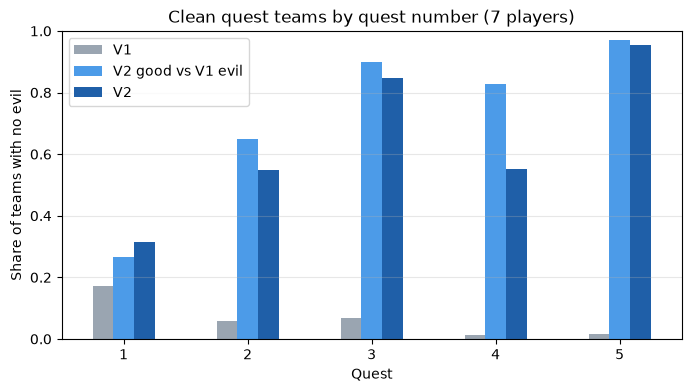

In [16]:
def clean_by_quest(states: list[GameState]) -> pd.Series:
    rows = [{"quest": q.quest_idx + 1, "clean": not (set(q.team) & s.evil_players())}
            for s in states for q in s.quests]
    return pd.DataFrame(rows).groupby("quest").clean.mean()


clean = pd.DataFrame({name: clean_by_quest(s) for name, s in states.items()})
ax = clean.plot.bar(figsize=(8, 4), color=colors, rot=0)
ax.set_ylim(0, 1); ax.set_xlabel("Quest"); ax.set_ylabel("Share of teams with no evil")
ax.set_title("Clean quest teams by quest number (7 players)"); ax.grid(alpha=.3, axis="y")
plt.show()

### All player counts

The same comparison for 5 to 10 players (2,000 games per point to keep the run time reasonable).

matchup,V1,V2 good vs V1 evil,V2
n_players,,,
5,0.096,0.973,0.963
6,0.068,0.948,0.948
7,0.092,0.966,0.954
8,0.054,0.910,0.866
9,0.104,0.966,0.946
10,0.035,0.906,0.878


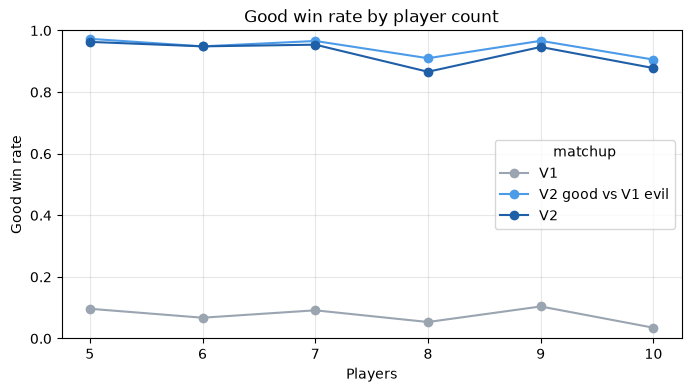

In [17]:
rows = []
for n in range(5, 11):
    for name, f in MATCHUPS.items():
        df = simulate(2000, n, f)
        rows.append({"n_players": n, "matchup": name, "good_win_rate": (df.winner == "good").mean()})
by_n = pd.DataFrame(rows).pivot(index="n_players", columns="matchup", values="good_win_rate")[list(MATCHUPS)]
display(by_n.round(3))

ax = by_n.plot(marker="o", figsize=(8, 4), color=colors)
ax.set_ylim(0, 1); ax.set_ylabel("Good win rate"); ax.set_xlabel("Players")
ax.set_title("Good win rate by player count"); ax.grid(alpha=.3)
plt.show()

## 9. Parameter sweeps

`sweep` varies one `V2Params` field (or one `BeliefModel` field, by prefixing it with
`belief.`) with everything else at its default, for 7 players.

### How often should evil sabotage, now that failing gets noticed?

In V1, failing more was always better for evil because nobody learned from it. In V2 every
fail card narrows down who is evil, so one might expect evil to do better by failing less and
staying hidden. The V1 curve is shown for reference.

,V1 good win rate,V2 good win rate,V2 clean teams
0.2,0.925,0.990,0.408
0.4,0.669,0.982,0.482
0.6,0.316,0.966,0.547
0.8,0.091,0.952,0.602
1.0,0.009,0.945,0.648


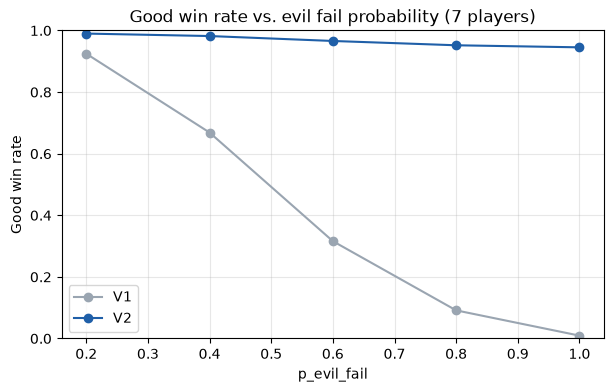

In [18]:
def sweep(param: str, values: Sequence[float], base: V2Params = V2Params(),
          n_games: int = 1500, n_players: int = 7, seed: int = 0) -> pd.DataFrame:
    rows = []
    for v in values:
        if param.startswith("belief."):
            params = replace(base, belief=replace(base.belief, **{param.removeprefix("belief."): v}))
        else:
            params = replace(base, **{param: v})
        df = simulate(n_games, n_players, belief_factory(params), seed=seed)
        rows.append({param: v, "good_win_rate": (df.winner == "good").mean(),
                     "evil_by_rejections": (df.reason == "5 rejected proposals").mean(),
                     "clean_team_share": df.clean_team_share.mean()})
    return pd.DataFrame(rows).set_index(param)


fail_values = [0.2, 0.4, 0.6, 0.8, 1.0]
v2_fail = sweep("p_evil_fail", fail_values)
v1_fail = pd.Series({v: (simulate(1500, 7, probabilistic_factory(PolicyParams(p_evil_fail=v))).winner
                         == "good").mean() for v in fail_values})

display(pd.DataFrame({"V1 good win rate": v1_fail, "V2 good win rate": v2_fail.good_win_rate,
                      "V2 clean teams": v2_fail.clean_team_share}).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(v1_fail.index, v1_fail.values, marker="o", color=colors[0], label="V1")
ax.plot(v2_fail.index, v2_fail.good_win_rate, marker="o", color=colors[2], label="V2")
ax.set_xlabel("p_evil_fail"); ax.set_ylabel("Good win rate"); ax.set_ylim(0, 1)
ax.set_title("Good win rate vs. evil fail probability (7 players)"); ax.legend(); ax.grid(alpha=.3)
plt.show()

### Which kind of evidence matters?

* **`belief.vote_weight`:** how much good players trust vote evidence (0 = learn from quest
  results only).
* **`propose_beta`:** how strongly a good leader prefers low-suspicion players
  (0 = ignore beliefs when proposing).
* **`vote_tolerance`:** how much less safe than their own best team a good voter will accept.
  Too strict causes rejection chains, too loose lets evil teams through.

belief.vote_weight,0.00,0.25,0.50,0.75,1.00
good_win_rate,0.434,0.855,0.952,0.971,0.977
evil_by_rejections,0.000,0.002,0.004,0.003,0.003


propose_beta,0.0,2.0,4.0,8.0,16.0
good_win_rate,0.251,0.653,0.887,0.952,0.971
evil_by_rejections,0.001,0.001,0.002,0.004,0.003


vote_tolerance,-0.1,0.0,0.1,0.2,0.4
good_win_rate,0.960,0.978,0.952,0.883,0.547
evil_by_rejections,0.013,0.007,0.004,0.001,0.000


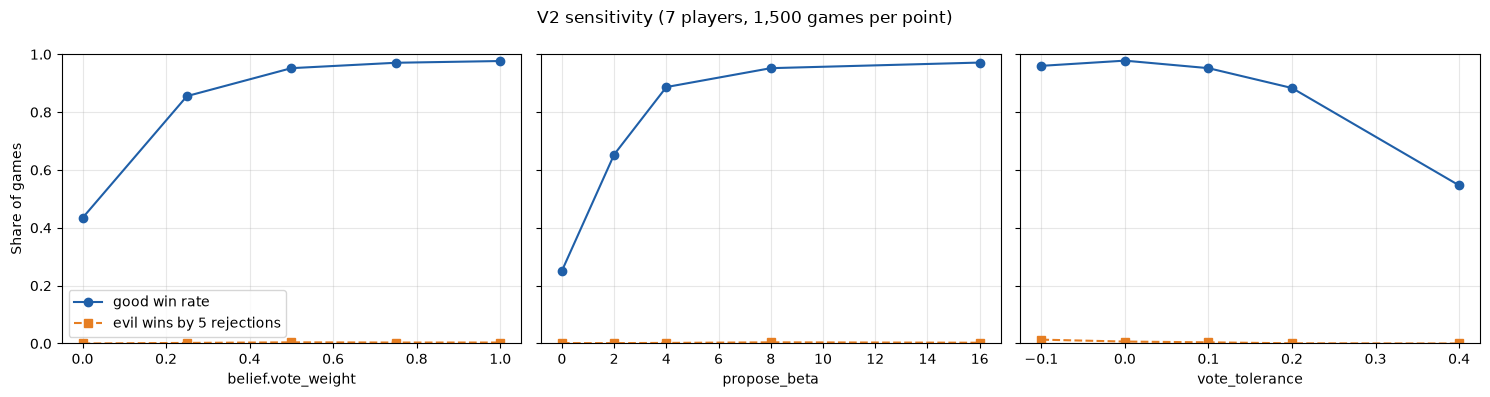

In [19]:
sweeps = {
    "belief.vote_weight": [0.0, 0.25, 0.5, 0.75, 1.0],
    "propose_beta": [0.0, 2.0, 4.0, 8.0, 16.0],
    "vote_tolerance": [-0.1, 0.0, 0.1, 0.2, 0.4],
}
results = {param: sweep(param, values) for param, values in sweeps.items()}
for param, res in results.items():
    display(res[["good_win_rate", "evil_by_rejections"]].T.round(3))

fig, axes = plt.subplots(1, len(sweeps), figsize=(15, 4), sharey=True)
for ax, (param, res) in zip(axes, results.items()):
    ax.plot(res.index, res.good_win_rate, marker="o", color=colors[2], label="good win rate")
    ax.plot(res.index, res.evil_by_rejections, marker="s", ls="--", color="#e67e22",
            label="evil wins by 5 rejections")
    ax.set_xlabel(param); ax.set_ylim(0, 1); ax.grid(alpha=.3)
axes[0].set_ylabel("Share of games"); axes[0].legend()
fig.suptitle("V2 sensitivity (7 players, 1,500 games per point)")
plt.tight_layout(); plt.show()

### How much do evil's votes give away?

By default good players' `BeliefModel` expects evil to approve 90% of teams containing evil
and 30% of all-good teams, which is exactly what V2 evil does. Here evil's *real* voting gets
less revealing while good players keep the same (now wrong) model. At "approve 55% / 55%",
evil votes exactly like the model's good players, so votes carry no information at all, and
good is also misled because it still expects the old pattern.

,evil approves teams with evil,evil approves all-good teams,good win rate,clean teams
0,0.90,0.30,0.952,0.602
1,0.80,0.40,0.929,0.580
2,0.70,0.50,0.892,0.550
3,0.55,0.55,0.761,0.474


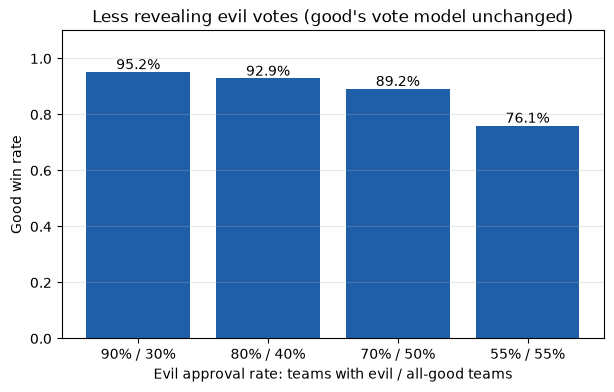

In [20]:
tells = [(0.9, 0.3), (0.8, 0.4), (0.7, 0.5), (0.55, 0.55)]
rows = []
for with_evil, no_evil in tells:
    params = replace(V2Params(), p_evil_approve_with_evil=with_evil, p_evil_approve_no_evil=no_evil)
    df = simulate(1500, 7, belief_factory(params))
    rows.append({"evil approves teams with evil": with_evil, "evil approves all-good teams": no_evil,
                 "good win rate": (df.winner == "good").mean(), "clean teams": df.clean_team_share.mean()})
tell = pd.DataFrame(rows)
display(tell.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
labels = [f"{w:.0%} / {n:.0%}" for w, n in tells]
ax.bar(labels, tell["good win rate"], color=colors[2])
for i, r in enumerate(tell["good win rate"]):
    ax.text(i, r + 0.01, f"{r:.1%}", ha="center")
ax.set_ylim(0, 1.1); ax.set_ylabel("Good win rate")
ax.set_xlabel("Evil approval rate: teams with evil / all-good teams")
ax.set_title("Less revealing evil votes (good's vote model unchanged)"); ax.grid(alpha=.3, axis="y")
plt.show()

## 10. Takeaways and what's next

**Findings (7 players unless stated)**

* **Learning flips the game.** Good's win rate goes from 9.2% (V1) to 96.3% (V2) over 5,000
  games, and stays at 87–97% for every player count. Quest teams with no evil on them go from
  7% to 61%. The cost is more deliberation: about 7 proposals and 3 rejections per game instead
  of 4 and 0.5, yet evil still wins on the vote track in under 1% of games.
* **The beliefs are accurate.** The three most-suspected players are 63% likely to be the evil
  ones after quest 1, 86% after quest 2 and 93% after quest 3. A random guess gets 43%.
* **Votes carry most of the signal.** Ignoring votes (`vote_weight = 0`) drops good's win rate
  to 43%. Learning from fail counts alone is still a big step up from V1, but most of the gain
  comes from evil's voting pattern. Good also has to *act* on its beliefs:
  with random team picks (`propose_beta = 0`) good wins only 25%.
* **Failing less doesn't help evil hide.** V2 good's win rate only moves from 99% to 94.5% as
  `p_evil_fail` goes from 0.2 to 1.0. Evil's votes give it away whether or not it fails, so
  holding back fail cards only costs it quests.
* **Evil faces a real dilemma.** When evil votes less revealingly than good expects, good's win
  rate falls from 95% to 76%. It doesn't fall further because evil also stops pushing its own
  teams through: hiding in the vote costs evil the votes it needs.
* **V2 evil barely benefits from its own adaptations** (96.7% vs. 96.3% good wins with V1 evil).
  Trusted-looking teams and occasional blending in can't offset the voting tell.

**Why good wins so often here.** This is not a claim that Avalon favours good. Evil in V2 is
still naive: it backs its own teams 90% of the time, fails at the first opportunity and doesn't
coordinate. There is also no Merlin/Assassin, and in real Avalon the assassination is evil's
main way back from three lost quests. V3 and V4 restore that balance.

**Known simplifications in V2**

* The `BeliefModel` treats good voters as approving at a flat rate, while V2 good players
  actually vote on their beliefs. Tempering (`vote_weight`) absorbs some of this mismatch.
* Team *proposals* are not used as evidence yet (e.g. an evil leader putting an ally on the team).
* Evil players don't coordinate, so two evil players on one team can both fail and expose
  themselves.

**Next versions** (see the README for details)

* **V3: Special roles.** Merlin, Assassin, Percival, Morgana, Mordred, Oberon. Merlin's
  knowledge and the Assassin's guess plug into the same belief machinery: the Assassin can
  run a tracker over "who is Merlin?" using how accurately each player voted.
* **V4: Strategic evil.** Coordinated fail cards, failing less early to stay hidden, and
  modelling good players' trackers more precisely.
* **V5: Learned vote models.** Fit the `BeliefModel` vote probabilities from simulated games
  instead of setting them by hand.